# Amazon Prime movies and TV shows analysis

## Project Objective

To analyze Amazon Prime Video content and identify trends, popular genres, countries and release patterns.

## Tools Used
-Python
-Pandas
-Numpy
-Matplotlib
-Seaborn
-Jupyter Notebook 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('../Dataset/amazon_prime_titles.csv')
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,The Grand Seduction,Don McKellar,"Brendan Gleeson, Taylor Kitsch, Gordon Pinsent",Canada,"March 30, 2021",2014,NaN,113 min,"Comedy, Drama",A small fishing village must procure a local d...
1,s2,Movie,Take Care Good Night,Girish Joshi,"Mahesh Manjrekar, Abhay Mahajan, Sachin Khedekar",India,"March 30, 2021",2018,13+,110 min,"Drama, International",A Metro Family decides to fight a Cyber Crimin...
2,s3,Movie,Secrets of Deception,Josh Webber,"Tom Sizemore, Lorenzo Lamas, Robert LaSardo, R...",United States,"March 30, 2021",2017,NaN,74 min,"Action, Drama, Suspense",After a man discovers his wife is cheating on ...
3,s4,Movie,Pink: Staying True,Sonia Anderson,"Interviews with: Pink, Adele, Beyoncé, Britney...",United States,"March 30, 2021",2014,NaN,69 min,Documentary,"Pink breaks the mold once again, bringing her ..."
4,s5,Movie,Monster Maker,Giles Foster,"Harry Dean Stanton, Kieran O'Brien, George Cos...",United Kingdom,"March 30, 2021",1989,NaN,45 min,"Drama, Fantasy",Teenage Matt Banting wants to work with a famo...


In [3]:
# check the numbers of rows and columns
print('Dataset Shape:',df.shape)

# display dataset information
print('\nDataset Information:')
df.info()

Dataset Shape: (9668, 12)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9668 entries, 0 to 9667
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       9668 non-null   object
 1   type          9668 non-null   object
 2   title         9668 non-null   object
 3   director      7585 non-null   object
 4   cast          8435 non-null   object
 5   country       672 non-null    object
 6   date_added    155 non-null    object
 7   release_year  9668 non-null   int64 
 8   rating        9331 non-null   object
 9   duration      9668 non-null   object
 10  listed_in     9668 non-null   object
 11  description   9668 non-null   object
dtypes: int64(1), object(11)
memory usage: 906.5+ KB


In [4]:
# check missing values in each column
df.isnull().sum()

show_id            0
type               0
title              0
director        2083
cast            1233
country         8996
date_added      9513
release_year       0
rating           337
duration           0
listed_in          0
description        0
dtype: int64

In [5]:
# filling missing values in selected columns

columns=['director','cast','country','rating']

for col in columns:
    df[col]=df[col].fillna('Unknown')

# check missing values after filling
df[columns].isnull().sum()

director    0
cast        0
country     0
rating      0
dtype: int64

In [6]:
# check the total number of duplicate rows
df.duplicated().sum()

0

In [7]:
# display all column names in the dataset

df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

In [8]:
# count movies and TV shows
content_type=df['type'].value_counts()

# display the results
content_type

type
Movie      7814
TV Show    1854
Name: count, dtype: int64

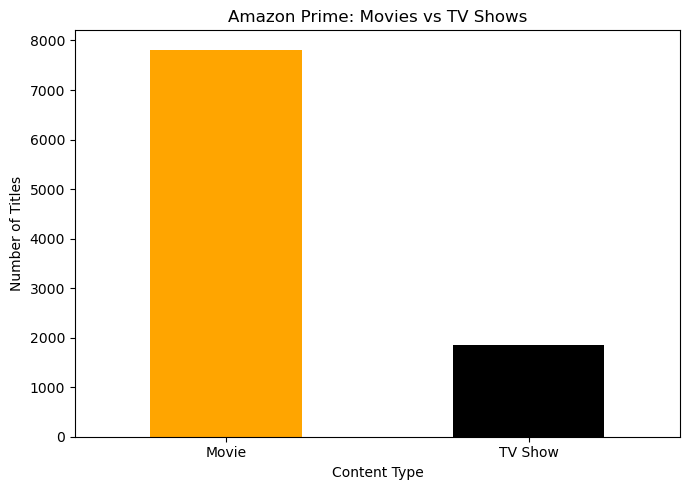

In [15]:
# create a bar chart of movies vs TV shows

plt.figure(figsize=(7,5))

content_type.plot(kind='bar',color=['orange','black'])

plt.title('Amazon Prime: Movies vs TV Shows')
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')
plt.xticks(rotation=0)

plt.tight_layout()

# save graph in visualizations folder
plt.savefig('../Visualizations/Movies_vs_TV_Shows.png', bbox_inches='tight')

plt.show()

In [10]:
# find the top 10 most common genres on amazon prime

genres=df['listed_in'].str.split(', ').explode()

top_genres=genres.value_counts().head(10)

# display the top 10 genres
top_genres

listed_in
Drama               3687
Comedy              2099
Action              1657
Suspense            1501
Kids                1085
Documentary          993
Special Interest     980
Horror               875
Romance              674
Animation            547
Name: count, dtype: int64

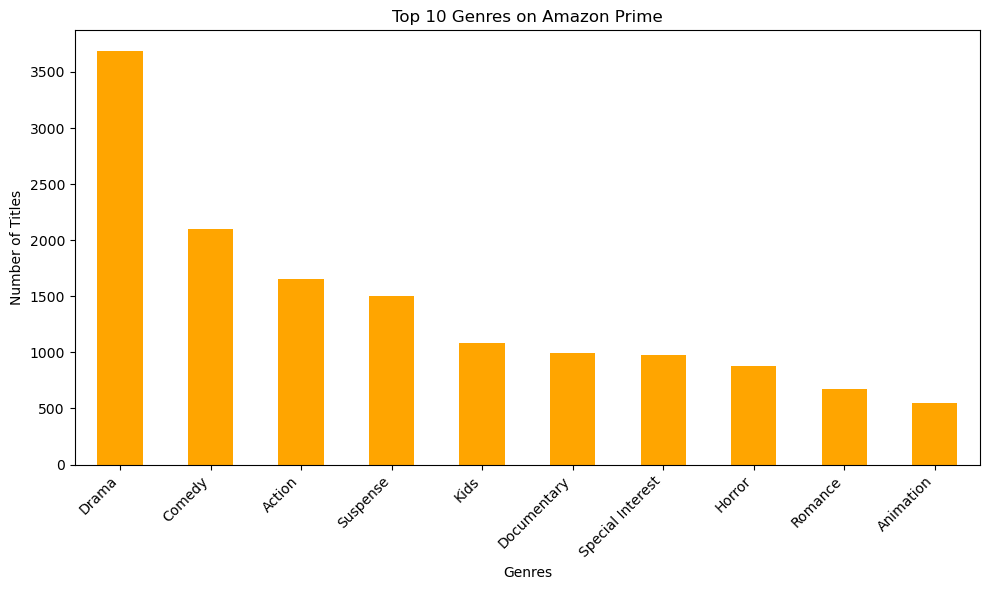

In [11]:
# create and save the top 10 genres graph

plt.figure(figsize=(10,6))

top_genres.plot(kind='bar', color='orange')

plt.title('Top 10 Genres on Amazon Prime')
plt.xlabel('Genres')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()

# save graph in visualizations folder
plt.savefig('../Visualization/Top_10_Genres.png',bbox_inches='tight')

plt.show()

In [16]:
# create the visualizations folder if it does not exist
import os

os.makedirs('../Visualizations',exist_ok=True)
print('Visualizations folder ready')

Visualizations folder ready


In [17]:
# find the top 10 countries producing amazon prime content

countries=df['country'].str.split(',').explode()

# remove unknown values and count countries
top_countries=countries[countries !='Unknown'].value_counts().head(10)

# display the top 10 countries
top_countries

country
United States      292
India              238
United Kingdom      48
 United States      42
Canada              25
 United Kingdom     19
 France             14
Italy               10
 Canada             10
Spain                9
Name: count, dtype: int64

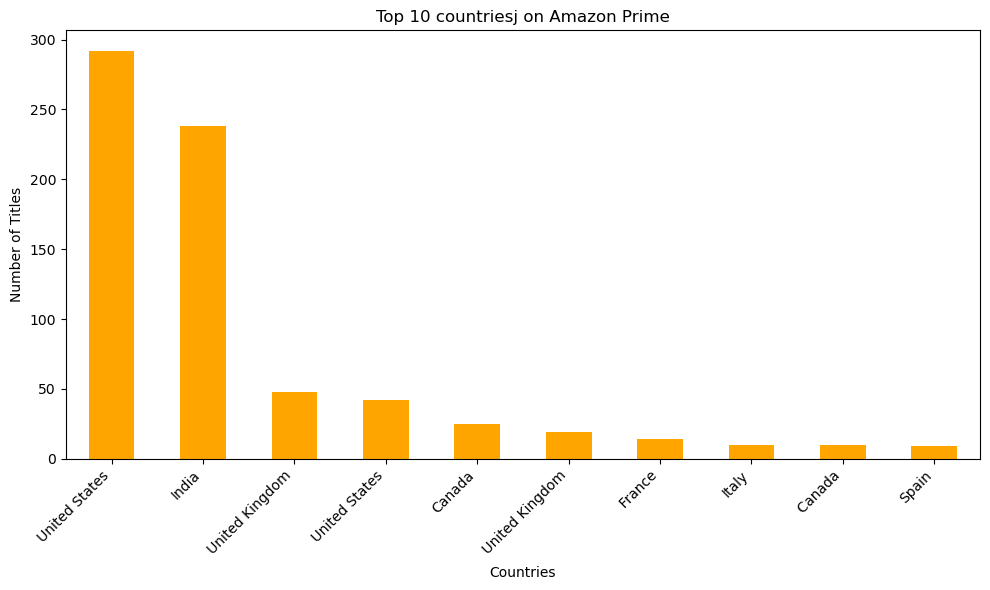

In [19]:
# create and save the top 10 countries graph

plt.figure(figsize=(10,6))

top_countries.plot(kind='bar',color='orange')

plt.title('Top 10 countriesj on Amazon Prime')
plt.xlabel('Countries')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()

# save graph in visualizations folder
plt.savefig('../Visualizations/Top_10_Countries.png',bbox_inches='tight')

plt.show()

In [20]:
# count the number of titles released each year

yearly_content=df['release_year'].value_counts().sort_index()

# displayj yearly content count
yearly_content

release_year
1920       3
1922       2
1923       1
1924       1
1925       8
        ... 
2017     562
2018     623
2019     929
2020     962
2021    1442
Name: count, Length: 100, dtype: int64

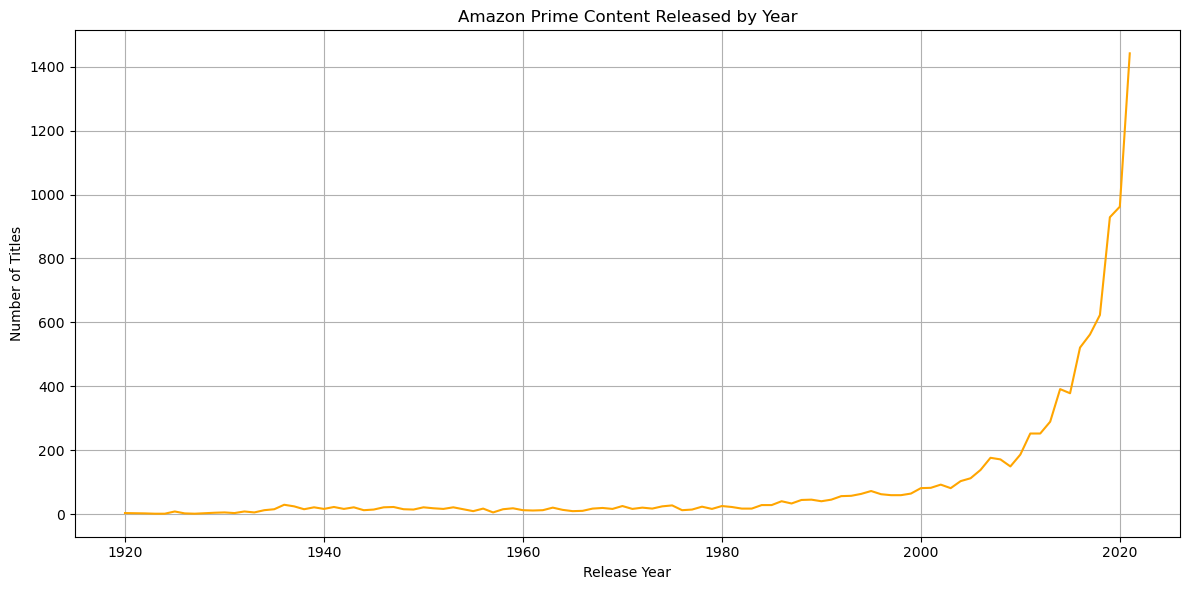

In [22]:
# create and save the yearly content release graph

plt.figure(figsize=(12,6))

yearly_content.plot(kind='line',color='orange')

plt.title('Amazon Prime Content Released by Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.grid(True)

plt.tight_layout()

# save  graph in visualization folder
plt.savefig('../Visualizations/Content_Released_by_Year.png', format='png')

plt.show()

In [24]:
# find the top 10 coutent rating on Amazon prime
ratings=df['rating'].value_counts().head(10)

# display the top 10 ratings
ratings

rating
13+        2117
16+        1547
ALL        1268
18+        1243
R          1010
PG-13       393
7+          385
Unknown     337
PG          253
NR          223
Name: count, dtype: int64

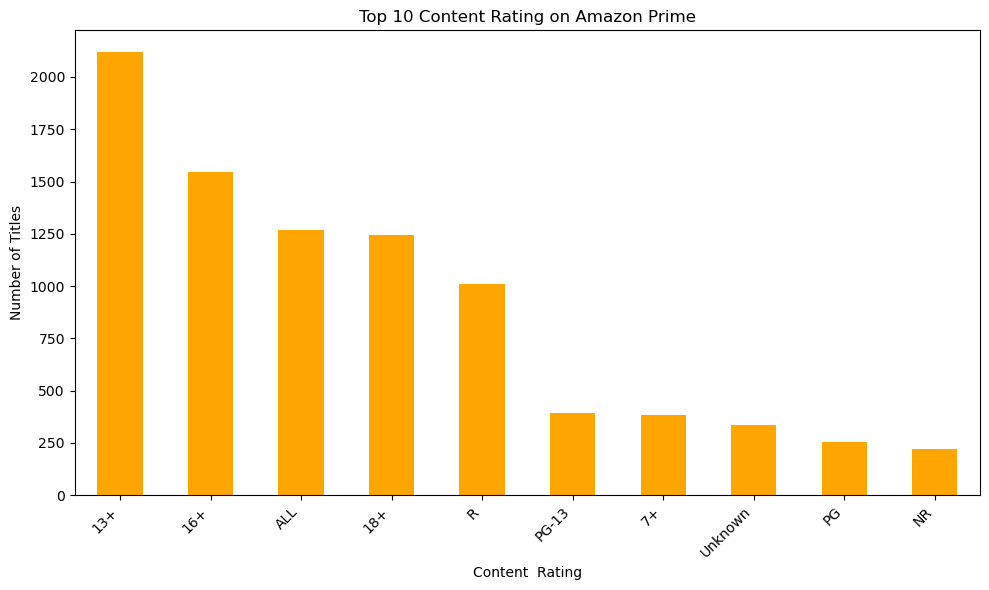

In [26]:
# create and save the content rating graph

plt.figure(figsize=(10,6))

rating.plot(kind='bar',color='orange')

plt.title('Top 10 Content Rating on Amazon Prime')
plt.xlabel('Content  Rating')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45,ha='right')

plt.tight_layout()

# save graph in visualizations folder
plt.savefig('../Visualizations/Content_Rating.png',format='png')

plt.show()
           

# Project Conclusion

- Amazon Prime has more Movies than TV Shows.
- The platform offers content across various genres.
- Content is available from different countries.
- The dataset shows content release trends over the years.
- Different content rating are available on Amazon Prime.

This project helped analze Amazon Prime Video content using Python and Data visualization